# Darstellung von Daten 1 - Histogramme

## Einleitung

Wie wir beim letzten Mal gesehen haben, sind Messwerte nie exakt, sie streuen. Wir wollen uns heute damit beschäftigen, wie wir diese Daten mit Hilfe von Python graphisch darstellen können. Wir verwenden python, um direkt eine professionelle Möglichkeit der Datendarstellung zu nutzen. Excel ist unter Wissenschaftlern recht verpönt.

Bevor ihr eigens aus Experimenten gewonnene Daten nun auswertet, wollen wir die typischen Analysen an Dummydaten durchexerzieren. Für einen 60m-Sprint wurden die handgestoppten Zeiten jedes einzelnen Laufs festgehalten.

| Lauf | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|----------|----------|----------|----------|----------|----------|----------|----------|----------|----------|----------|
| Zeit in s | 9.89 | 10.22 | 10.41 | 10.8 | 10.01 | 10.2 | 9.57 | 9.95 | 10.1 | 9.23 |

Um diesen Daten später arbeiten zu können, wurden sie auch im Textdokument "sprint60m.txt" abgelegt.

## Laden der Module von Python

Um unsere Daten darstellen zu können, verwenden wir das Modul "matplotlib", zum Einlesen der Daten "pandas". Führen Sie die folgenden Zeilen aus, indem Sie die Box anklicken und dann oben auf den Ausführen-Pfeil ▶ klicken. Wollen Sie die weiteren Code-Beispiele in einer lokalen Python-Installation ausführen (z.B. Thonny), so müssen Sie sich selber darum kümmern, dass die Module installiert sind.

In [7]:
# Modul zum Handling von Datendateien
import pandas as pd

# Modul zur Darstellung von Daten
import matplotlib.pyplot as plt

## Einlesen der Daten

Die Daten aus der Datei "sprint60m.txt" laden wir mithilfe der folgenden Zeilen und überprüfen in der Ausgabe, ob alles gut aussieht.

In [8]:
# Daten aus Datei einlesen
data = pd.read_csv("sprint60m.txt")

# Daten zur Kontrolle ausgeben
print(data)

# Datenreihe in Liste umwandeln für spätere Verwendung
times = data["Zeiten in s"].to_list()


   Zeiten in s
0         9.89
1        10.22
2        10.41
3        10.80
4        10.01
5        10.20
6         9.57
7         9.95
8        10.10
9         9.23


## Erzeugung des Diagramms

Die folgenden Zeilen erstellen uns das Diagramm. Das können Sie nun ausprobieren. Wir können aber auch noch ein bisschen was einstellen. So können Sie z.B. mal die Breite der Balken oder deren Farbe ändern. Finden Sie, wo das möglich ist?

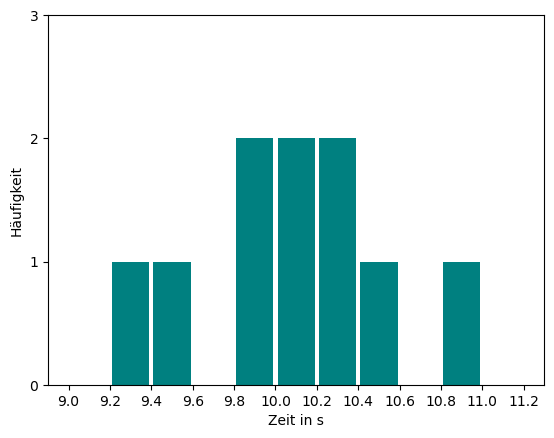

In [9]:
# Diagrammvariablen erstellen
fig, ax = plt.subplots()

# Histogramm erstellen
bins = [9, 9.2, 9.4, 9.6, 9.8, 10, 10.2, 10.4, 10.6, 10.8, 11, 11.2] # Abschnitte für Balken definieren
ax.hist(times, bins, rwidth=0.9, color="teal") # Erstellung des Histogramms mit den Daten, den Abschnitten, der Balkenbreite und der Balkenfarbe

# Achsen passend mit Zahlen beschriften lassen
ax.set_xticks(bins)
ax.set_yticks([0,1,2,3])

# Achsen beschriften
ax.set_xlabel('Zeit in s')
ax.set_ylabel('Häufigkeit')

#Diagramm anzeigen
plt.show()

## Besserer Code

Vielleicht ist einigen von euch aufgestossen, dass wir die "bins" und die y-Achsen-Skalierung mit von Hand geschriebenen Listen erzeugt haben. Hätten wir andere Daten müssten wir diese immer wieder aufwändig neu anpassen. Stattdessen können wir versuchen, dies einwenig zu automatisieren. Warnung: Der folgende Code erfordert, dass man mitdenkt.

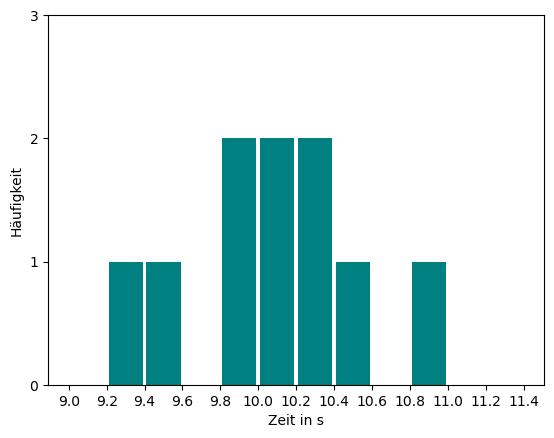

In [10]:
# Diagrammvariablen erstellen
fig, ax = plt.subplots()

# Histogramm erstellen
x_min = 9
x_max = 11.2
x_step = 0.2
x_bins = [x_min]
while x_bins[-1] < x_max:
    x_bins.append(x_bins[-1] + x_step)
ax.hist(times, x_bins, rwidth=0.9, color="teal") # Erstellung des Histogramms mit den Daten, den Abschnitten, der Balkenbreite und der Balkenfarbe

# Achsen passend mit Zahlen beschriften lassen
ax.set_xticks(x_bins)
y_min = 0
y_max = 3
y_step = 1
y_bins = [y_min]
while y_bins[-1] < y_max:
    y_bins.append(y_bins[-1] + y_step)
ax.set_yticks(y_bins)

# Achsen beschriften
ax.set_xlabel('Zeit in s')
ax.set_ylabel('Häufigkeit')

#Diagramm anzeigen
plt.show()

## Eigene Messung

Erstellen Sie nun selbst eine Datendatei und ein passendes Diagramm aus einer eigenen Messung. Bestimme dazu die Fallzeit einer Stahlkugel aus 1.5 m Höhe. Führen Sie mindestens 10 Messungen durch. Den Programmcode können Sie zu grossen Teilen von oben kopieren und müssen ihn nur noch etwas anpassen.

In [6]:
import subprocess

# Funktion zum Überprüfen, ob ein Modul bereits installiert ist
def check(package):
    ans = subprocess.run(["pip", "list"], capture_output=True, text=True)
    return package in ans.stdout

# Funktion, um ein Modul zu installieren
def install(package):
    subprocess.check_call(["pip", "install", package])

# Module, die installiert sein müssen
packages = ["matplotlib", "pandas"]

# Iteration durch die Modulliste
for package in packages:
    if not check(package):
        install(package)

<class 'OSError'>: [Errno 138] emscripten does not support processes.